In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
ds = xr.load_dataset("ERA5_features/grib_files/soil_moist_layer1.grib", engine="cfgrib")
var_daily1 = ds.swvl1.groupby(ds.swvl1.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/soil_moist_layer1.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
ds = xr.load_dataset("ERA5_features/grib_files/soil_moist_layer2.grib", engine="cfgrib")
var_daily2 = ds.swvl2.groupby(ds.swvl2.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/soil_moist_layer2.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
var_daily = var_daily1 + var_daily2
var_daily = var_daily.reset_coords(['number', 'step'], drop=True)

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month == 2) & (day == 29)))

In [8]:
ds_oro = xr.load_dataset("ERA5_features/grib_files/orography_1deg_res.grib", engine="cfgrib")
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

Ignoring index file 'ERA5_features/grib_files/orography_1deg_res.grib.5b7b6.idx' incompatible with GRIB file


In [9]:
g = 9.80665
lat = ds_oro.latitude
land_frac = ds_oro.lsm
mount_filt = xr.where(ds_oro.z/g < 1000, 1, 0)
land_filt = xr.where(land_frac > 0.5, 1, 0)

In [10]:
weights = np.cos(np.deg2rad(lat))*mount_filt*land_filt
weights.name = "weights"

In [11]:
lon_min = 4
lon_max = 42
lat_max = 72
lat_min = 59

var_daily_regmean = var_daily.sel(longitude=slice(lon_min,lon_max), latitude=slice(lat_max,lat_min)).weighted(weights).mean(dim=['longitude', 'latitude'])

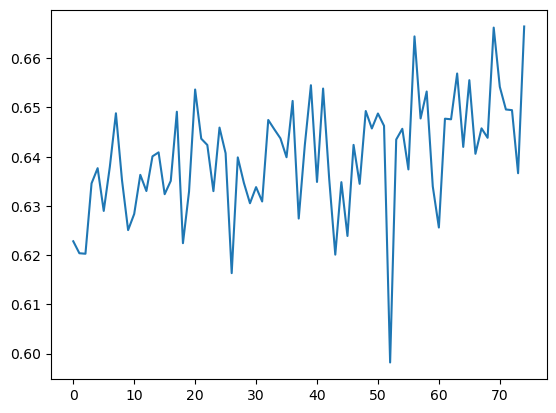

In [12]:
var_seasonmean_regmean = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")).mean(dim='date')
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)

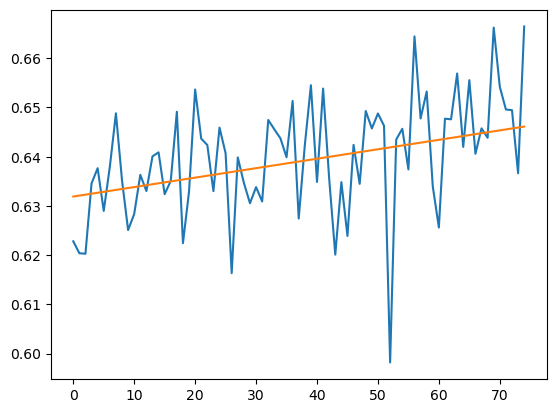

In [13]:
fit_par = np.polyfit(var_seasonmean_regmean[:60].year, var_seasonmean_regmean[:60], 1)
var_seasonmean_regmean_gws = np.polyval(fit_par, var_seasonmean_regmean.year)

plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean_gws)

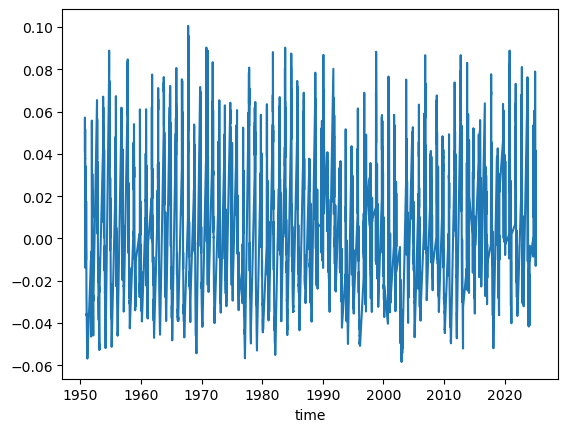

In [14]:
var_daily_regmean_detr = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")) - var_seasonmean_regmean_gws[:, np.newaxis]
var_daily_regmean_detr = var_daily_regmean_detr.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)
var_daily_regmean_detr.plot()

In [15]:
var_7dMean_regmean_detr = var_daily_regmean_detr.rolling(time=7, min_periods=7, center=True).mean() 
month = var_7dMean_regmean_detr.time.dt.month
day = var_7dMean_regmean_detr.time.dt.day
var_7dMean_regmean_detr = var_7dMean_regmean_detr.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

var_7dMean_regmean_detr_train = var_7dMean_regmean_detr.sel(time=slice("1950-07", "2010-06"))

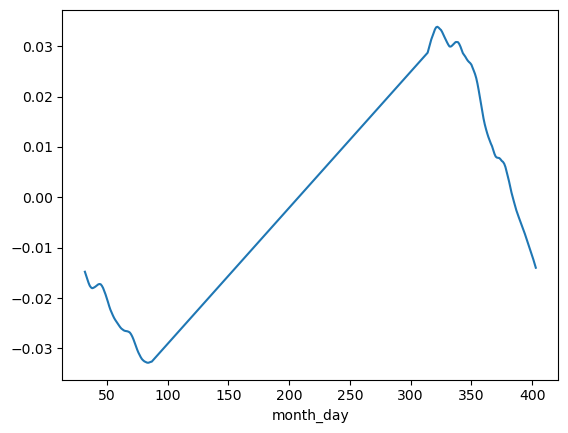

In [16]:
var_7dMean_regmean_detr_anom = var_7dMean_regmean_detr.groupby('month_day') - var_7dMean_regmean_detr_train.groupby('month_day').mean()
var_7dMean_regmean_detr_train.groupby('month_day').mean().plot()

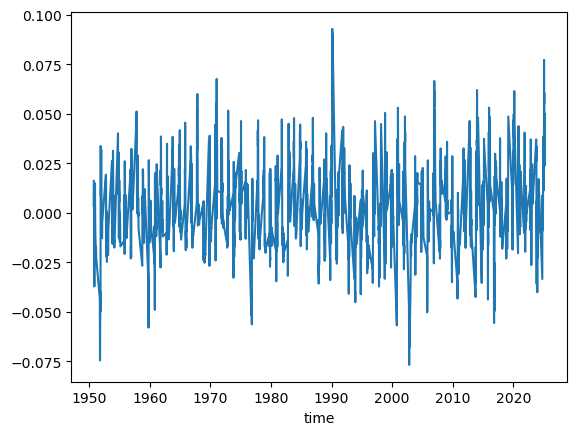

In [17]:
var_7dMean_regmean_detr_anom.plot()

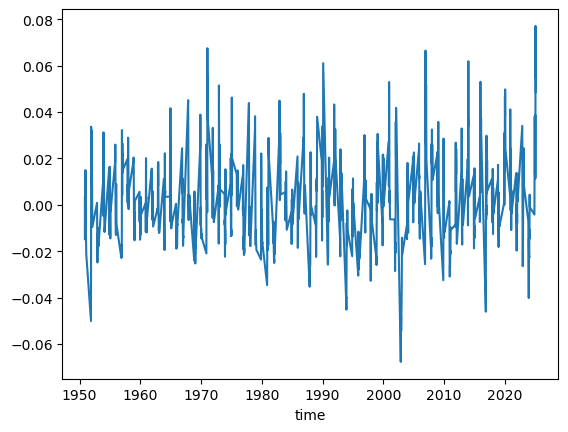

In [18]:
month = var_7dMean_regmean_detr_anom.time.dt.month
day = var_7dMean_regmean_detr_anom.time.dt.day
var_7dMean_regmean_detr_anom_week0 = var_7dMean_regmean_detr_anom.sel(time = ((month == 12) & (day >= 4)) | (month == 1) | ((month == 2) & (day <= 25)))
var_7dMean_regmean_detr_anom_week1 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 27)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 18)))
var_7dMean_regmean_detr_anom_week2 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 20)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 11)))
var_7dMean_regmean_detr_anom_week3 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_7dMean_regmean_detr_anom_week4 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28)))
var_7dMean_regmean_detr_anom_week5 = var_7dMean_regmean_detr_anom.sel(time = ((month == 10) & (day >= 30)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 21)))
var_7dMean_regmean_detr_anom_week6 = var_7dMean_regmean_detr_anom.sel(time = ((month == 10) & (day >= 23)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 14)))
var_7dMean_regmean_detr_anom_week7 = var_7dMean_regmean_detr_anom.sel(time = ((month == 10) & (day >= 16)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 7)))
var_7dMean_regmean_detr_anom_week3.plot()

In [19]:
df_var_week3 = var_7dMean_regmean_detr_anom_week3.to_dataframe(name='soil_moist_upper')
df_var_week3 = df_var_week3.drop(['month_day'], axis=1)
df_var_week3

,soil_moist_upper
time,
1950-11-13,-0.014823
1950-11-14,-0.007586
1950-11-15,-0.002079
1950-11-16,0.001626
1950-11-17,0.003784
...,...
2025-01-31,0.058564
2025-02-01,0.056857
2025-02-02,0.055146


In [20]:
df_var_week4 = var_7dMean_regmean_detr_anom_week4.to_dataframe(name='soil_moist_upper')
df_var_week4 = df_var_week4.drop(['month_day'], axis=1)
df_var_week4

,soil_moist_upper
time,
1950-11-06,-0.034527
1950-11-07,-0.036405
1950-11-08,-0.037248
1950-11-09,-0.036426
1950-11-10,-0.034032
...,...
2025-01-24,0.056190
2025-01-25,0.054950
2025-01-26,0.055053


In [21]:
df_var_week5 = var_7dMean_regmean_detr_anom_week5.to_dataframe(name='soil_moist_upper')
df_var_week5 = df_var_week5.drop(['month_day'], axis=1)
df_var_week5

,soil_moist_upper
time,
1950-10-30,-0.024741
1950-10-31,-0.025904
1950-11-01,-0.026717
1950-11-02,-0.027669
1950-11-03,-0.029083
...,...
2025-01-17,0.070504
2025-01-18,0.074738
2025-01-19,0.077153


In [19]:
df_var_week6 = var_7dMean_regmean_detr_anom_week6.to_dataframe(name='soil_moist_upper')
df_var_week6 = df_var_week6.drop(['month_day'], axis=1)
df_var_week6

,soil_moist_upper
time,
1950-10-23,0.003242
1950-10-24,-0.001080
1950-10-25,-0.006550
1950-10-26,-0.011977
1950-10-27,-0.016722
...,...
2025-01-10,0.011340
2025-01-11,0.014120
2025-01-12,0.017844


In [20]:
df_var_week7 = var_7dMean_regmean_detr_anom_week7.to_dataframe(name='soil_moist_upper')
df_var_week7 = df_var_week7.drop(['month_day'], axis=1)
df_var_week7

,soil_moist_upper
time,
1950-10-16,0.011330
1950-10-17,0.011821
1950-10-18,0.013221
1950-10-19,0.013364
1950-10-20,0.013108
...,...
2025-01-03,0.023654
2025-01-04,0.021091
2025-01-05,0.019077


In [19]:
df_var_week0 = var_7dMean_regmean_detr_anom_week0.to_dataframe(name='soil_moist_upper')
df_var_week0 = df_var_week0.drop(['month_day'], axis=1)
df_var_week0

,soil_moist_upper
time,
1950-12-04,-0.006165
1950-12-05,-0.007495
1950-12-06,-0.008821
1950-12-07,-0.009888
1950-12-08,-0.010747
...,...
2025-02-21,0.031149
2025-02-22,0.036515
2025-02-23,0.041468


In [20]:
df_var_week1 = var_7dMean_regmean_detr_anom_week1.to_dataframe(name='soil_moist_upper')
df_var_week1 = df_var_week1.drop(['month_day'], axis=1)
df_var_week1

,soil_moist_upper
time,
1950-11-27,-0.003837
1950-11-28,-0.003389
1950-11-29,-0.003589
1950-11-30,-0.003987
1950-12-01,-0.004194
...,...
2025-02-14,0.030308
2025-02-15,0.028524
2025-02-16,0.026736


In [21]:
df_var_week2 = var_7dMean_regmean_detr_anom_week2.to_dataframe(name='soil_moist_upper')
df_var_week2 = df_var_week2.drop(['month_day'], axis=1)
df_var_week2

,soil_moist_upper
time,
1950-11-20,-0.002890
1950-11-21,-0.005374
1950-11-22,-0.006150
1950-11-23,-0.006249
1950-11-24,-0.006083
...,...
2025-02-07,0.042632
2025-02-08,0.041544
2025-02-09,0.039865


In [25]:
df_var_week3.to_csv('sm_upper_NE_week3_detr.csv')

In [22]:
df_var_week4.to_csv('sm_upper_NE_week4_detr.csv')
df_var_week5.to_csv('sm_upper_NE_week5_detr.csv')

In [21]:
df_var_week6.to_csv('sm_upper_NE_week6_detr.csv')
df_var_week7.to_csv('sm_upper_NE_week7_detr.csv')

In [22]:
df_var_week0.to_csv('sm_upper_NE_week0_detr.csv')
df_var_week1.to_csv('sm_upper_NE_week1_detr.csv')
df_var_week2.to_csv('sm_upper_NE_week2_detr.csv')